In [11]:
%pip install openpyxl


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [12]:
import pandas as pd
import datetime
import math
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel(io = "Online_Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [14]:
df["Quantity"].value_counts()

 1        148227
 2         81829
 12        61063
 6         40868
 4         38484
           ...  
-472           1
-161           1
-1206          1
-272           1
-80995         1
Name: Quantity, Length: 722, dtype: int64

In [15]:
df["UnitPrice"].value_counts()

1.25      50496
1.65      38181
0.85      28497
2.95      27768
0.42      24533
          ...  
84.21         1
46.86         1
28.66         1
156.45        1
224.69        1
Name: UnitPrice, Length: 1630, dtype: int64

In [16]:
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]
df = df[df["CustomerID"].notnull()]
df.shape

(397884, 8)

In [17]:
df["Country"].value_counts()[:5]

United Kingdom    354321
Germany             9040
France              8341
EIRE                7236
Spain               2484
Name: Country, dtype: int64

In [18]:
df = df[df["Country"] == "United Kingdom"]
df.shape

(354321, 8)

In [19]:
df["sale_amount"] = df["Quantity"] * df["UnitPrice"]

In [20]:
df.shape

(354321, 9)

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 354321 entries, 0 to 541893
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    354321 non-null  object        
 1   StockCode    354321 non-null  object        
 2   Description  354321 non-null  object        
 3   Quantity     354321 non-null  int64         
 4   InvoiceDate  354321 non-null  datetime64[ns]
 5   UnitPrice    354321 non-null  float64       
 6   CustomerID   354321 non-null  float64       
 7   Country      354321 non-null  object        
 8   sale_amount  354321 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 27.0+ MB


In [22]:
df["CustomerID"] = df["CustomerID"].astype(int)

In [23]:
df.groupby("CustomerID")["sale_amount"].sum().sort_values(ascending = False)[:5]

CustomerID
18102    259657.30
17450    194550.79
16446    168472.50
17511     91062.38
16029     81024.84
Name: sale_amount, dtype: float64

In [25]:
df.groupby(["InvoiceNo", "StockCode"])["InvoiceNo"].count().mean()

1.028702077315023

In [26]:
aggregations = {
    "InvoiceDate": "max",
    "InvoiceNo": "count",
    "sale_amount": "sum"
}

cust_df = df.groupby("CustomerID").agg(aggregations)
cust_df = cust_df.rename(columns = {"InvoiceDate": "Recency",
                                    "InvoiceNo": "Frequency",
                                    "sale_amount": "Monetary"
                                    }
                        )
cust_df = cust_df.reset_index()
cust_df.head()

,CustomerID,Recency,Frequency,Monetary
0,12346,2011-01-18 10:01:00,1,77183.60
1,12747,2011-12-07 14:34:00,103,4196.01
2,12748,2011-12-09 12:20:00,4595,33719.73
3,12749,2011-12-06 09:56:00,199,4090.88
4,12820,2011-12-06 15:12:00,59,942.34


In [27]:
df["InvoiceDate"].sort_values()

0        2010-12-01 08:26:00
1        2010-12-01 08:26:00
2        2010-12-01 08:26:00
3        2010-12-01 08:26:00
4        2010-12-01 08:26:00
                 ...        
541879   2011-12-09 12:31:00
541892   2011-12-09 12:49:00
541890   2011-12-09 12:49:00
541891   2011-12-09 12:49:00
541893   2011-12-09 12:49:00
Name: InvoiceDate, Length: 354321, dtype: datetime64[ns]

In [28]:
import datetime as dt

cust_df["Recency"] = dt.datetime(2011, 12, 10) - cust_df["Recency"]
cust_df["Recency"] = cust_df["Recency"].apply(lambda x: x.days + 1)
print(cust_df.shape)
cust_df.head()

(3920, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12747,3,103,4196.01
2,12748,1,4595,33719.73
3,12749,4,199,4090.88
4,12820,4,59,942.34


(array([3.887e+03, 1.900e+01, 9.000e+00, 2.000e+00, 0.000e+00, 0.000e+00,
        1.000e+00, 1.000e+00, 0.000e+00, 1.000e+00]),
 array([3.75000000e+00, 2.59691050e+04, 5.19344600e+04, 7.78998150e+04,
        1.03865170e+05, 1.29830525e+05, 1.55795880e+05, 1.81761235e+05,
        2.07726590e+05, 2.33691945e+05, 2.59657300e+05]),
 <BarContainer object of 10 artists>)

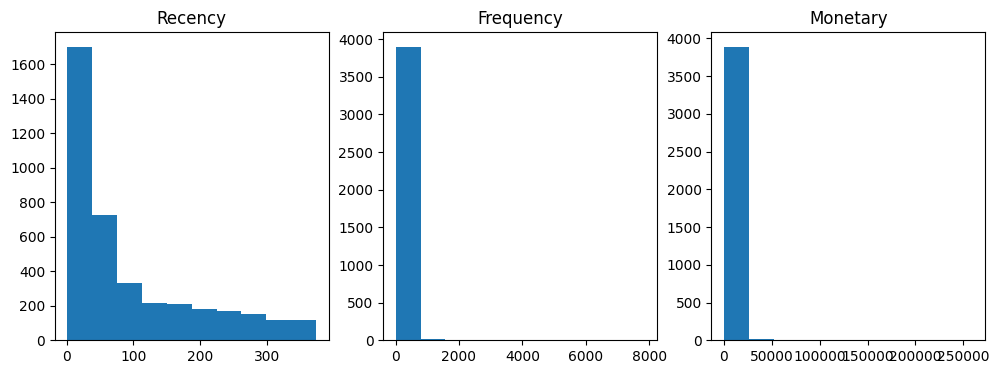

In [29]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize = (12, 4), nrows = 1, ncols = 3)
ax1.set_title("Recency")
ax1.hist(cust_df["Recency"])

ax2.set_title("Frequency")
ax2.hist(cust_df["Frequency"])

ax3.set_title("Monetary")
ax3.hist(cust_df["Monetary"])

In [30]:
cust_df[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,3920.000000,3920.000000,3920.000000
mean,92.742092,90.388010,1864.385601
std,99.533485,217.808385,7482.817477
min,1.000000,1.000000,3.750000
25%,18.000000,17.000000,300.280000
50%,51.000000,41.000000,652.280000
75%,143.000000,99.250000,1576.585000
max,374.000000,7847.000000,259657.300000


In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

X_features = cust_df[["Recency", "Frequency", "Monetary"]].values
X_features_scaled = StandardScaler().fit_transform(X_features)

kmeans = KMeans(n_clusters = 3, random_state = 0)
labels = kmeans.fit_predict(X_features_scaled)
cust_df["cluster_label"] = labels

print(np.round(silhouette_score(X_features_scaled, labels), 3))

0.592


In [34]:
def visualize_silhouette(cluster_lists, X_features):
    import matplotlib.cm as cm 

    n_cols = len(cluster_lists)
    fig, axs = plt.subplots(
    figsize=(4 * n_cols, 4),
    nrows=1,
    ncols=n_cols)

    for ind, n_cluster in enumerate(cluster_lists):
        clusterer = KMeans(n_clusters = n_cluster, max_iter = 500,
                           random_state = 0)
        cluster_labels = clusterer.fit_predict(X_features)

        sil_avg = silhouette_score(X_features, cluster_labels)
        sil_values = silhouette_samples(X_features, cluster_labels)

        y_lower = 10
        axs[ind].set_title(f"No. of Cluster: {n_cluster}\n"
                             f"Silhouette Score: {sil_avg:.3f}")
        axs[ind].set_xlabel("The 실루엣 coeff values")
        axs[ind].set_ylabel("Cluster Label")
        axs[ind].set_xlim([-.01, 1])
        axs[ind].set_ylim([0, len(X_features) + (n_cluster + 1) * 10])
        axs[ind].set_yticks([])
        axs[ind].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])

        for i in range(n_cluster):
            ith_cluster_sil_values = sil_values[cluster_labels == i]
            ith_cluster_sil_values.sort()

            size_cluster_i = ith_cluster_sil_values.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.nipy_spectral(float(i) / n_cluster)
            axs[ind].fill_betweenx(np.arange(y_lower, y_upper), 0,
                                  ith_cluster_sil_values, facecolor = color,
                                  edgecolor = color, alpha = 0.7)
            axs[ind].text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
            y_lower = y_upper + 10
        axs[ind].axvline(x = sil_avg, color = "red", linestyle = "--")

In [35]:
def visualize_kmeans_plot_multi(cluster_lists, X_features):
    from sklearn.decomposition import PCA

    n_cols = len(cluster_lists)
    fig, axs = plt.subplots(figsize = (4 * n_cols, 4), nrows = 1,
                            ncols = n_cols)

    pca = PCA(n_components = 2)
    pca_transformed = pca.fit_transform(X_features)
    dataframe = pd.DataFrame(pca_transformed, columns = ["PCA1", "PCA2"])

    for ind, n_cluster in enumerate(cluster_lists):
        clusterer = KMeans(n_clusters = n_cluster, max_iter = 500,
                           random_state = 0)
        cluster_labels = clusterer.fit_predict(pca_transformed)
        dataframe["cluster"] = cluster_labels

        unique_labels = np.unique(clusterer.labels_)
        markers = ["o", "s", "^", "x", "*"]

        for label in unique_labels:
            label_df = dataframe[dataframe["cluster"] == label]
            if label == -1:
                cluster_legend = "Noise"
            else:
                cluster_legend = "Cluster" + str(label)
            axs[ind].scatter(x = label_df["PCA1"], y = label_df["PCA2"],
                             s = 70, edgecolor = "k", marker = markers[label],
                             label = cluster_legend)
        axs[ind].set_title("No. of Cluster: " + str(n_cluster))
        axs[ind].legend(loc = "upper right")
    plt.show() 

/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_34961/1204579201.py:27: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axs[ind].scatter(x = label_df["PCA1"], y = label_df["PCA2"],
/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_34961/1204579201.py:27: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axs[ind].scatter(x = label_df["PCA1"], y = label_df["PCA2"],
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.

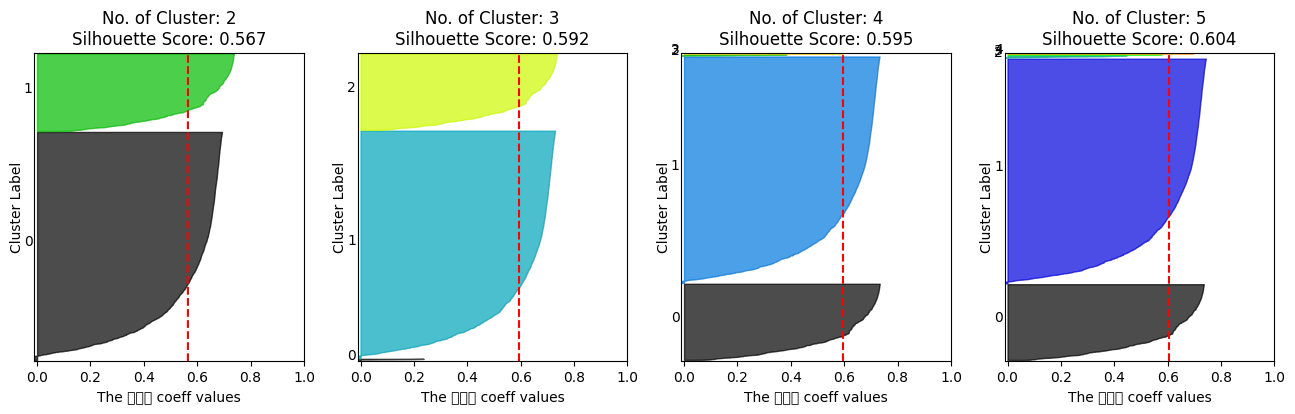

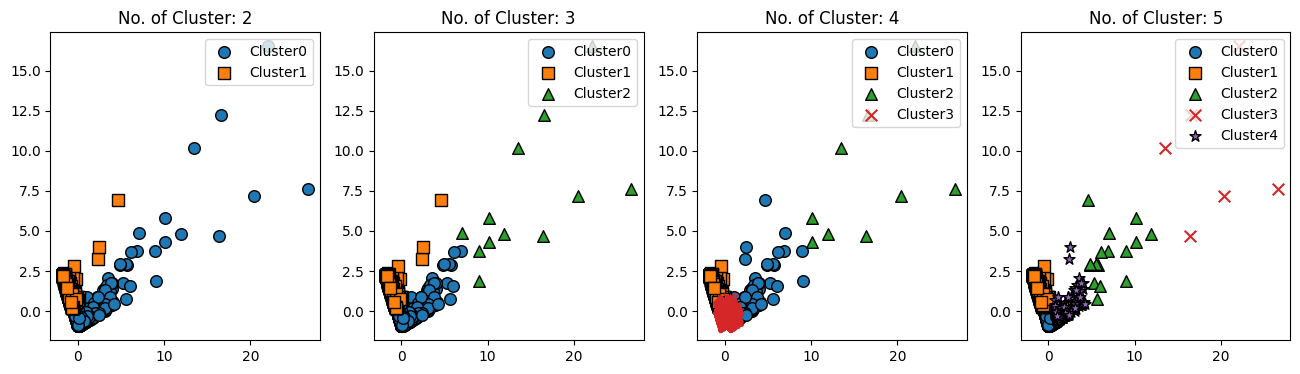

In [36]:
visualize_silhouette([2, 3, 4, 5], X_features_scaled)
visualize_kmeans_plot_multi([2, 3, 4, 5], X_features_scaled)

In [37]:
cust_df["Recency_log"] = np.log1p(cust_df["Recency"])
cust_df["Frequency_log"] = np.log1p(cust_df["Frequency"])
cust_df["Monetary_log"] = np.log1p(cust_df["Monetary"])

X_features = cust_df[["Recency_log", "Frequency_log", "Monetary_log"]].values
X_features_scaled = StandardScaler().fit_transform(X_features)

kmeans = KMeans(n_clusters = 3, random_state = 0)
labels = kmeans.fit_predict(X_features_scaled)
cust_df["cluster_label_log"] = labels

print(np.round(silhouette_score(X_features_scaled, labels), 3))

0.303


/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_34961/1204579201.py:27: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axs[ind].scatter(x = label_df["PCA1"], y = label_df["PCA2"],
/var/folders/4v/tf2tg78s6yd4n5__j_8dggcm0000gn/T/ipykernel_34961/1204579201.py:27: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  axs[ind].scatter(x = label_df["PCA1"], y = label_df["PCA2"],
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/yoon/Documents/Machine_Learning/ML/.venv/lib/python3.10/site-packages/IPython/core/pylabtools.

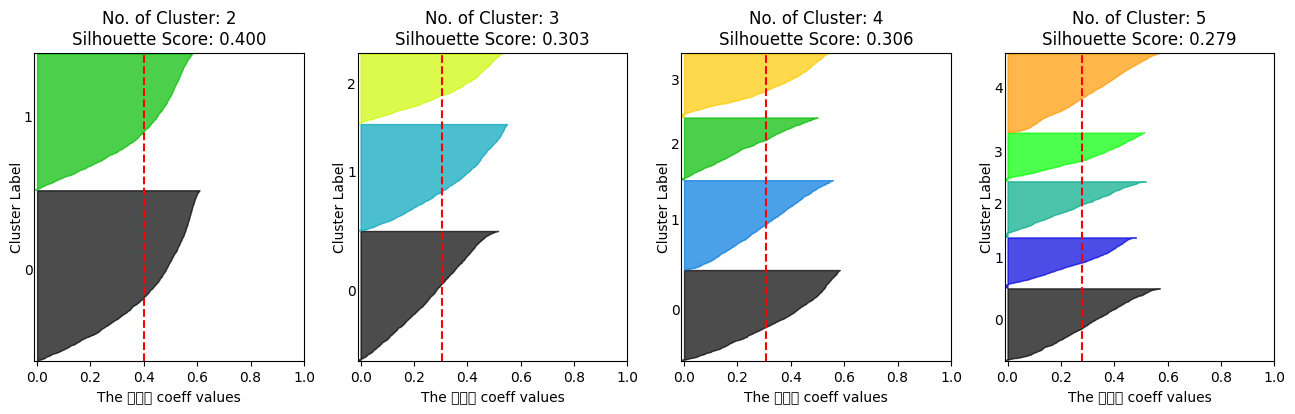

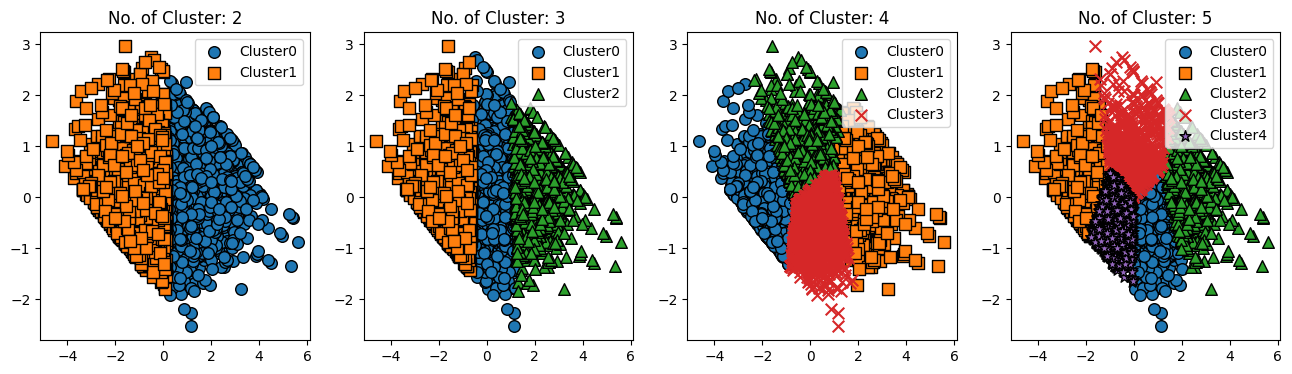

In [38]:
visualize_silhouette([2, 3, 4, 5], X_features_scaled)
visualize_kmeans_plot_multi([2, 3, 4, 5], X_features_scaled)